# LangChain Core& Tool Call

###핵심 개념 정리

- Tool: LLM이 필요할 때 호출하는 외부 기능(예: 웹 검색, 계산기, DB 질의).

- Tool Call: 모델이 “이 질문은 검색이 필요하네”처럼 도구 호출 의사결정을 내려 실제로 도구를 실행하는 단계.

- Agent: “언제 어떤 도구를 쓸지” 스스로 판단해 도구 호출 → 결과 반영 → 답변 생성을 반복 실행하는 실행자.

- bind_tools: LLM에 사용할 도구들을 등록해 도구 호출 가능한 모델로 만드는 LangChain 방식.











# 단계 1. AI 모델 준비
- Google Gemini와 OpenAI GPT 같은 AI 모델을 불러옵니다.  
- 동시에 요청 횟수를 제한하는 ‘속도 제한 장치(Rate Limiter)’도 둡니다.  
  → 고객센터에 전화를 한꺼번에 너무 많이 걸리지 않게 막는 역할과 비슷합니다.

In [ ]:
!pip install -U langchain langchain_core langchain_community langchain_google_genai tavily-python
# 👉 필요한 라이브러리 설치 (LangChain + Google Gemini + Tavily 검색 툴)

In [3]:
# Load environment variables in a file called .env
# API 키 설정 
import os
from dotenv import load_dotenv
load_dotenv(override=True)


True

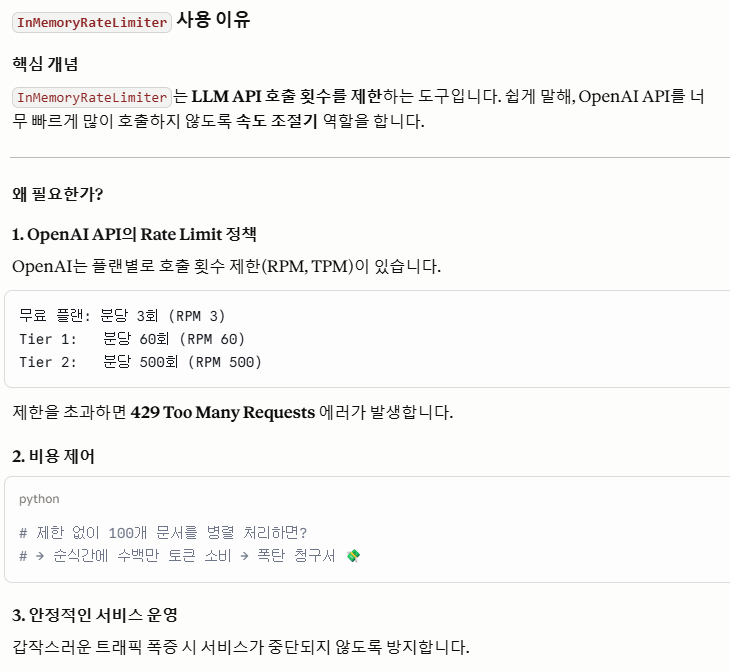

In [69]:
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_openai import ChatOpenAI  # LangChain 라이브러리에서 ChatOpenAI 가져오기

# 👉 요청 제한기(Rate Limiter)와 ChatOpenAI 모델 불러오기
# from langchain_openai import ChatOpenAI
# 고객지원 시나리오에서도 동일한 호출 제한 가정 (분당 10회)
request_throttle = InMemoryRateLimiter(
    requests_per_second=0.167,  # 👉 초당 약 0.167회 → 분당 10회 제한
    check_every_n_seconds=0.1,  # 👉 0.1초마다 요청 횟수 체크
    max_bucket_size=10,         # 👉 최대 10개까지 한 번에 처리 가능
)

# Rate Limiter를 적용한 LLM 인스턴스
cs_llm = ChatOpenAI(
    model="gpt-5-mini",  # 👉 사용할 OpenAI 모델 지정
    rate_limiter=request_throttle, # 👉 위에서 만든 요청 제한기 적용
)

# 간단 동작 확인용 테스트 질문(도메인: 고객지원)
cs_llm.invoke("고객 응대란 무엇인지 한 문장으로 설명해줘!")
# 👉 모델이 정상 작동하는지 테스트


AIMessage(content='고객 응대란 고객의 문의·불만·요구를 경청하고 신속하고 적절하게 해결해 고객 만족을 실현하는 활동이다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 236, 'prompt_tokens': 21, 'total_tokens': 257, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 192, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-DrGl9RP3fqeWOTlVq0qj1X2QyPFza', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019eceee-1cdd-7d41-93c3-7369781ea072-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 21, 'output_tokens': 236, 'total_tokens': 257, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 192}})


# 단계 2. 멀티턴 대화의 뼈대 만들기
- 사람 질문(HumanMessage), 시스템 지침(SystemMessage), AI 답변(AIMessage)을 정리해 대화 기록을 만듭니다.  
- 이렇게 하면 AI가 대화 맥락을 이해하고 친절한 톤으로 답할 수 있습니다.


### LLM이 답변하는 방법

In [70]:
# 1. HumanMessage를 이용한 방법
# LangChain에서 대화 메시지 타입 세 가지를 불러옵니다:
# - HumanMessage: 사용자의 질문
# - SystemMessage: 답변 규칙·조건
# - AIMessage: AI가 생성한 응답
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage

support_system_msg = SystemMessage(content="""아래 [문의]에 대해 적절하게 답하시오.
답변은 2문장 이내로 하고, 친절하고 정확한 어조로 답하세요.""")
# 👉 시스템 메시지: "답변은 2문장 이내, 친절하게" 규칙 설정

customer_msg = HumanMessage(content="환불 절차를 간단히 설명해줘!")
# 👉 고객이 실제로 묻는 질문 입력

conversation_log = [support_system_msg, customer_msg]
# 👉 대화 기록을 리스트로 구성

cs_response = cs_llm.invoke(conversation_log)
cs_response
# 👉 대화 기록을 모델에 전달하고 응답 받기

# Chat 모델의 출력은 AIMessage라는 형식으로 변환됩니다.
print(cs_response.content)
# 👉 실제 답변 내용 출력


환불은 보통 주문번호와 영수증을 준비해 고객센터에 요청하고(필요 시 상품 반품), 판매처의 검수·승인 후 진행됩니다. 환불금은 원결제수단으로 입금되며 처리기간은 보통 3~7영업일(신용카드는 청구주기에 따라 더 걸릴 수 있음)입니다.


# 단계 3. 프롬프트 체인 만들기
- “프롬프트”는 AI에게 지시하는 대본 같은 것입니다.  
- 이를 LLM과 연결해 체인으로 만들면, 질문이 들어올 때마다 같은 규칙으로 대답합니다.

In [71]:
# 2. ChatPromptTemplate을 이용한 방법
from langchain_core.prompts import ChatPromptTemplate
# 👉 대화 프롬프트(질문 틀) 생성 도구

# 입력 변수가 {inquiry}인 템플릿 (도메인: 고객지원)
support_prompt = ChatPromptTemplate([
    ('system', '''아래 [문의]에 답변하시오.
답변은 2문장 이내로 하고, 친절하고 정확한 어조로 답하세요.'''),
    ('user', '''[문의]: {inquiry}''')
])
# 👉 system 규칙 + user 질문을 템플릿으로 정의



# 프롬프트와 LLM(cs_llm)을 | 로 연결하여 체인 구성
support_chain = support_prompt | cs_llm
# 👉 프롬프트와 모델을 연결해 하나의 체인으로 사용

cs_resp = support_chain.invoke({'inquiry': "고객 FAQ와 맞춤 스크립트의 차이가 뭐야?"})
print(cs_resp.content)
# 👉 템플릿에 질문 전달 → 답변 생성


고객 FAQ는 자주 묻는 질문과 그에 대한 표준화된 답변을 모아 누구나 빠르게 참고할 수 있게 만든 정적 문서입니다. 반면 맞춤 스크립트는 특정 고객 상황·목적·채널에 맞춰 문구·대화 흐름을 조정한 동적 템플릿으로 상담원이나 챗봇이 개인화된 응대를 할 때 사용됩니다.


In [72]:
# 입력 변수가 1개일 때는 값만 전달해도 됨
cs_resp = support_chain.invoke("교환/반품 정책이 뭐야?")
print(cs_resp.content)
# 👉 간단한 호출 방법 (문자열만 넣어도 됨)
# 참고: 외부 근거가 부족하면 환각이 발생할 수 있습니다.
# 👉 포인트: AI가 틀린 내용을 말할 수도 있음 (주의)

교환/반품 정책은 판매처와 상품에 따라 다르며, 일반적으로 상품 수령일로부터 7~30일 이내에 사용·훼손이 없는 상태와 영수증(또는 주문번호) 제시가 필요합니다. 정확한 기간·비용·제외 품목(위생용품·세일상품 등)은 구매하신 쇼핑몰의 고객센터나 주문내역 페이지에서 확인해 주세요.


# 단계 4. 외부 검색 도구 연결
- Tavily 검색 같은 도구를 붙여서, AI가 최신 정책이나 정보를 직접 찾아보고 답하게 합니다.  
- 예: “현재 환불 규정 알려줘” → AI가 도구를 써서 검색 후 답변.

In [4]:
from langchain_community.tools.tavily_search import TavilySearchResults  # Tavily 웹 검색 도구
# 👉 외부 검색을 위한 Tavily 툴 불러오기
# 고객지원 검색용 Tavily 인스턴스
support_search = TavilySearchResults(
    max_results=3,            # 👉 검색 최대 3개
    include_answer=True,      # 👉 요약 포함
    include_raw_content=True, # 👉 원문 포함
)

C:\Users\jino7\AppData\Local\Temp\ipykernel_29068\2856698428.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults  # Tavily 웹 검색 도구
C:\Users\jino7\AppData\Local\Temp\ipykernel_29068\2856698428.py:4: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  support_search = TavilySearchResults(


In [5]:
# 고객지원 검색용 Tavily 인스턴스 간단 검색
cs_search_docs = support_search.invoke("교환과 환불 정책의 차이는?")
print(cs_search_docs)
# 👉 검색 실행 (AI가 참고할 수 있는 자료 수집)

[{'title': '17. 교환/반품/환불 정책 정의', 'url': 'https://hyeyun133.tistory.com/55', 'content': "랑콤 교환정책\n\n아래 육육걸즈의 경우도 교환이 아닌 재주문을 해야 하는데 이 때 결제 금액 자체도 환불처리하지 않고 예치금으로 적립시켜 버린다. 아무래도 결제수단에 따라 환불이 완료되기까지 1~3일 정도의 시간이 소요되므로 교환과 환불 사이의 타협점을 찾은 것으로 보인다. 어쨌든 이 방법도 결국 재주문을 넣는 것이기 때문에 정확한 의미의 상품 '교환'은 아니다.\n\n육육걸즈 교환정책\n\n그 외 보통 쇼핑몰의 교환절차는 게시글에 직접 상품명과 옵션을 기재하여 교환신청을 넣는다. 이 때 상품을 반송하고(2,500원) 다른 상품으로 교환(2,500원)하므로 교환 시 배송비는 5,000원이 부담된다. 배송비를 지불하는 방법에는 반품하는 상품에 현금을 동봉하거나, 선입금하고 교환신청 시 입금자명을 기재하거나, 환불 시 차감하는 방법이 있다.\n\n이렇게 교환 상품을 기재하는 경우는 다른 상품, 다른 옵션으로도 교환 가능하므로 소비자 입장에서 가장 교환에 제한이 없지만 CS에서 교환 건마다 직접 교환 상품을 지정해주어야 한다는 단점이 있다.\n\n플라이모델 교환정책\n\n  \n\n관리자가 '교환 후 상품'을 직접 지정해주어야 한다\n\n반면 소비자의 자유도를 낮추고 CS CAPA에 따라 같은 상품의 다른 옵션으로만 교환하도록 제한한다면 무신사의 방법이 가장 절충안이라고 볼 수 있다. 무신사의 경우는 교환 요청 시 상품 옵션을 변경할 수 있고 만약 출고 이후라면 배송비도 바로 결제할 수 있다.\n\n무신사 교환정책 [...] 무신사 교환정책\n\n> 마치며앞서 정의한대로 교환에는 3가지 경우의 수가 있다.  \n>   \n> 1) 주문 상품 금액 = 교환 상품 금액 : 교환 완료 처리 됨  \n> 2) 주문 상품 금액 > 교환 상품 금액 : (주문 상품 금액 - 교환 상품 금액) 환불 처리 후 교환 완료 처리

# 단계 5 LLM에 Tool 연결하기

In [9]:
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_openai import ChatOpenAI  # LangChain 라이브러리에서 ChatOpenAI 가져오기

# 👉 요청 제한기(Rate Limiter)와 ChatOpenAI 모델 불러오기
# from langchain_openai import ChatOpenAI
# 고객지원 시나리오에서도 동일한 호출 제한 가정 (분당 10회)
request_throttle = InMemoryRateLimiter(
    requests_per_second=0.167,  # 👉 초당 약 0.167회 → 분당 10회 제한
    check_every_n_seconds=0.1,  # 👉 0.1초마다 요청 횟수 체크
    max_bucket_size=10,         # 👉 최대 10개까지 한 번에 처리 가능
)

# Rate Limiter를 적용한 LLM 인스턴스
cs_llm = ChatOpenAI(
    model="gpt-5-mini",  # 👉 사용할 OpenAI 모델 지정
    rate_limiter=request_throttle, # 👉 위에서 만든 요청 제한기 적용
)

In [10]:
# LLM에 Tool 연결하기
support_tools = [support_search]  # 👉 사용할 툴 목록 정의
cs_llm_with_tools = cs_llm.bind_tools(support_tools)

In [11]:
# 👉 LLM에 검색 툴 연결 → AI가 직접 검색 가능해짐
print(cs_llm_with_tools)  # 👉 툴이 등록된 모델 확인
print(cs_llm_with_tools.kwargs['tools'])  # 👉 등록된 툴 스키마 내부 확인

bound=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.5.3', 'langchain': '1.3.14', 'langchain-openai': '1.4.1'}}, rate_limiter=<langchain_core.rate_limiters.InMemoryRateLimiter object at 0x000001D89C1D7770>, profile={'name': 'GPT-5 Mini', 'release_date': '2025-08-07', 'last_updated': '2025-08-07', 'open_weights': False, 'max_input_tokens': 272000, 'max_output_tokens': 128000, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': False, 'image_url_inputs': True, 'pdf_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True, 'reasoning_effort_levels': ['none', 'low', 'medium', 'high', 'xhigh']}, client=<openai.resources.chat.completions.completions.Completions object at 0x000001D8C96

👉 프롬프트와 툴 연결 모델을 합쳐 체인 생성

In [12]:
#  ChatPromptTemplate을 이용한 방법
from langchain_core.prompts import ChatPromptTemplate
# 👉 대화 프롬프트(질문 틀) 생성 도구

# 입력 변수가 {inquiry}인 템플릿 (도메인: 고객지원)
support_prompt = ChatPromptTemplate([
    ('system', '''아래 [문의]에 답변하시오.
답변은 2문장 이내로 하고, 친절하고 정확한 어조로 답하세요.'''),
    ('user', '''[문의]: {inquiry}''')
])
# 👉 system 규칙 + user 질문을 템플릿으로 정의

In [13]:
#  프롬프트와 툴 연결 모델을 합쳐 체인 생성
support_tool_chain = support_prompt | cs_llm_with_tools

프롬프트와 툴 연결 모델을 합친 체인 답변 요청

In [14]:
# 프롬프트와 툴 연결 모델을 합쳐 체인 답변 요청
tool_call_msg = support_tool_chain.invoke("고객지원에서 FAQ, 지식베이스, 스크립트 에이전트의 차이를 알려줘.")
print(tool_call_msg)

content='FAQ는 자주 묻는 질문에 대한 짧은 Q&A 모음으로 고객이 빠르게 답을 찾도록 만들고, 지식베이스는 더 상세하고 구조화된 문서·가이드·문제해결 절차를 포함한 검색 가능한 레퍼런스입니다. 스크립트는 상담원이 통화·채팅 중 따라야 할 단계별 대화 템플릿이고, 에이전트는 그 스크립트와 지식베이스를 활용해 고객을 응대하는 사람(또는 AI 챗봇)을 뜻합니다.' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 646, 'prompt_tokens': 224, 'total_tokens': 870, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 512, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ECfv4woLrWnh2iAyqXeKr1P4yJai0', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--019fff02-649a-71c3-9faf-f95212455719-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 224, 'output_tokens': 646, 'total_tokens': 870, 'input_token_details': {'audio': 0,

In [16]:
# 👉 툴 호출 여부 확인 및 매핑된 실행 함수 준비
support_tool_map = {'tavily_search_results_json': support_search}  # 툴 이름 → 실제 함수 매핑

if tool_call_msg.tool_calls:
    invoked_tool_name = tool_call_msg.tool_calls[0]['name']  # 호출된 툴 이름 추출
    tool_exec = support_tool_map.get(invoked_tool_name)       # 해당 이름의 실행 함수 가져오기
    print(invoked_tool_name, tool_exec)                       # 호출된 툴 이름과 함수 확인용 출력
else:
    print("❌ 툴 호출이 존재하지 않습니다.")   

❌ 툴 호출이 존재하지 않습니다.


## 웹검색 답변 요청

In [17]:
#  LLM +툴 기반 답변 요청
tool_call_msg = support_tool_chain.invoke("현재 시점의 고객센터 관련 주요 이슈를 검색해줘")
print(tool_call_msg)

content='' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 235, 'prompt_tokens': 214, 'total_tokens': 449, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 192, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-ECfvN73wprVySC3WCfiDVAekqpUHP', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None} id='lc_run--019fff02-cbaf-7892-873d-e9eefa0d9c35-0' tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': '고객센터 관련 주요 이슈 2026 08 14 현재 시점'}, 'id': 'call_nvHYzon9jHFHW6W6ZhFrlFNX', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 214, 'output_tokens': 235, 'total_tokens': 449, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details

In [21]:
# 👉 툴 호출 여부 확인 및 매핑된 실행 함수 준비
support_tool_map = {'tavily_search_results_json': support_search}  # 툴 이름 → 실제 함수 매핑

if tool_call_msg.tool_calls:
    invoked_tool_name = tool_call_msg.tool_calls[0]['name']  # 호출된 툴 이름 추출
    tool_exec = support_tool_map.get(invoked_tool_name)       # 해당 이름의 실행 함수 가져오기
    print(invoked_tool_name, tool_exec)                       # 호출된 툴 이름과 함수 확인용 출력
else:
    print("❌ 툴 호출이 존재하지 않습니다.")   

tavily_search_results_json max_results=3 include_answer=True include_raw_content=True api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'))


# 도구 호출 및 실행

In [19]:
# 👉 프롬프트 없이 툴 연결 모델 직접 호출
tool_call_msg.tool_calls

[{'name': 'tavily_search_results_json',
  'args': {'query': '고객센터 관련 주요 이슈 2026 08 14 현재 시점'},
  'id': 'call_nvHYzon9jHFHW6W6ZhFrlFNX',
  'type': 'tool_call'}]

In [20]:
support_tool_msg = tool_exec.invoke(tool_call_msg.tool_calls[0])  # 👉 툴 실행 결과 수집


In [86]:
print(support_tool_msg)  # 👉 검색 결과 확인

content='[{"title": "2026년이야, 이제 \\"실제 상담원\\"이라고 말하는 게 사실은 AI 상담원들이랑 대화하는 거야. 행운을 빌게.. : r/Comcast", "url": "https://www.reddit.com/r/Comcast/comments/1qrjsnx/it_is_2026_you_are_now_talking_to_ai_agents_when?tl=ko", "content": "# 2026년이야, 이제 \\"실제 상담원\\"이라고 말하는 게 사실은 AI 상담원들이랑 대화하는 거야. 행운을 빌게.. : r/Comcast\\nSkip to main content2026년이야, 이제 \\"실제 상담원\\"이라고 말하는 게 사실은 AI 상담원들이랑 대화하는 거야. 행운을 빌게.. : r/Comcast\\n\\nOpen menu Open navigation 내가 예전에 소매업에서 일했었고 2) 나는 외향적이고 되게 친절한 편이거든. 그래도 진짜, 뭐지...\\n\\n참고로, (자기가 사람이라고 했던) AI 봇 이름은 Joy인데, 그리고 또, 나한테 장애 때문에 환불도 해줬어. 그러니까... 뭐, 그래도 신께서 축복하시길 바라야겠지???\\n\\n아무튼, 오늘 그녀(AI)가 친절했고 도움을 준 건 여전히 고맙긴 해... 근데 진짜, 아무튼 되게 흥미로웠어.\\n\\n나는 AI 괜찮아. 그냥 투명하게 공개하는 게 중요하다고 생각하고, 그리고 또, 기술 자체보다 이윤 추구가 더 큰 문제라고 봐. 기술 자체는 괜찮아. 근데 그걸 이윤을 위해 적용하는 방식은 아니지.\\n\\n Reply  Share \\n\\nMore replies\\n\\nImage 3: u/creeper73 avatar\\n\\ncreeper73\\n\\n•5mo ago\\n\\n사람들은 여전히 여기다 이상한 \'실시간 상담원\' 채팅 내용을 올릴 거고, 우리는 또 그걸 보고 말해줘야 할 거야\\n\\n Reply  Share \\n\\n[](\\n\\nGhostclip\\n\\